In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from scipy.optimize import curve_fit

In [3]:
##### 3.1.1
C = 100 * 10**(-9)
R = 1000
U_in = 1.44

f = np.array([10, 100, 500, 1000, 5000, 10000, 50000, 100000]) #betweeen 10Hz and 100kHz
U_out = np.array([1.44, 1.44, 1.36, 1.2, 0.44, 0.248, 0.08, 0.06])
phi = np.array([0, -3.7, -17, -33.5, -73, -83, -90, 150])

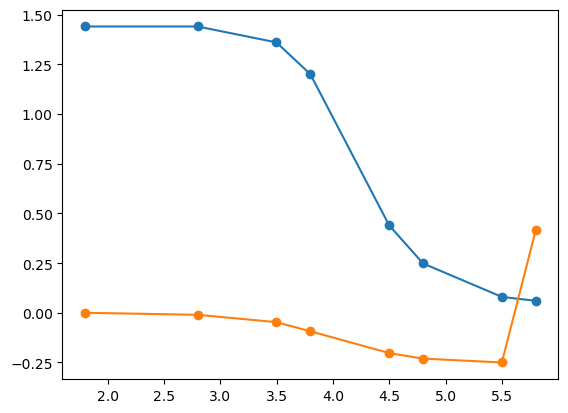

In [4]:
plt.plot(np.log10(f * 2 * np.pi), U_out / U_in * U_in, marker='o')
plt.plot(np.log10(f * 2 * np.pi), phi / 360, marker='o')

In [5]:
##### 3.1.2
C = 100 * 10**(-9)
R = 1000
print('theoretical:', 1 / (R * C))

theoretical: 10000.0


In [6]:
##### 3.1.3
# graphical discussion

In [7]:
##### 3.1.4
# roll-off
# d 20 * log(U_out / U_in) / d log(omega) [dB/dec]

In [8]:
##### 3.1.5
# plot with phase difference
# theoretical 1/sqrt(2)
# phi_cutoff??

In [9]:
##### 3.1.6
# phase difference of U_c and I_c
f = np.array([250, 1000, 2600, 5000, 7500])
U_c = np.array([0, 0, 0])
I_c = np.array([0, 0, 0])
phi = np.array([-90, -90, 90, 85, ...]) #+- 5°

In [10]:
#plt.plot(f * 2 * np.pi, U_c, marker='o')
#plt.plot(f * 2 * np.pi, I_c, marker='o')

In [19]:
##### 3.2.1
L = 0.01
C = 100 * 10**(-9)
R = 1000
U_in = 1.44
print('expected resonance omega =', 1 / np.sqrt(C * L))

f = np.array([    3,    3.15, 3.42, 3.59, 3.81, 4.02, 4.57, 4.76, 4.81, 5.18,  5.4, 5.5,   5.7,   6.04, 6.28, 6.45,  6.74, 7.6,  5.32, 5.26, 5.35, 5.06, 5.17])
U_out = np.array([0.34, 0.38, 0.44, 0.5,  0.58, 0.66, 0.96, 1.08, 1.1,  1.28,  1.3, 1.28,  1.2,   1.04, 0.91, 0.86,  0.74, 0.54, 1.3,  1.3,  1.3,  1.24, 1.28])
phi = np.array([  72.6, 71,   67,   65,   62,   58,   40,   32.4, 30,   8,    -5.5, -11.5, -22.6, -38,  -45,  -49.2, -55,  -65,  -1.3, 2.3,  -2.5, 16.6, 9.5])

expected resonance omega = 31622.776601683792


Text(0.5, 1.0, 'resonance curve')

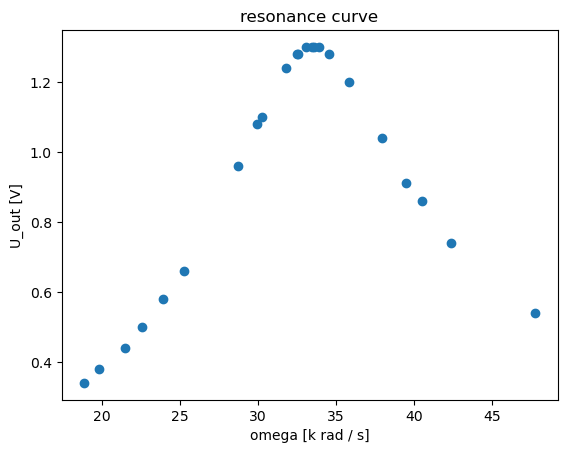

In [28]:
##### 3.2.2
plt.plot(f * 2 * np.pi, U_out, marker = 'o', linestyle='')
plt.xlabel('omega [k rad / s]')
plt.ylabel('U_out [V]')
plt.title('resonance curve')

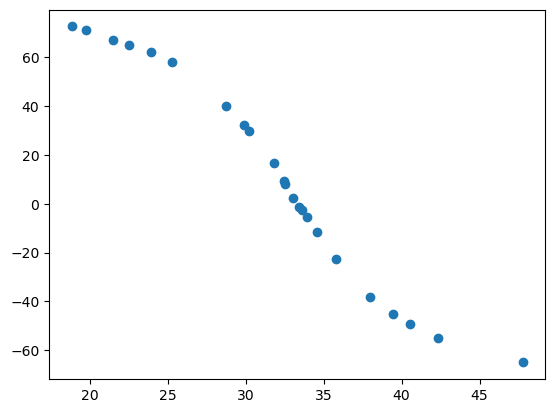

In [29]:
plt.plot(f * 2 * np.pi, phi, marker = 'o', linestyle='')

In [30]:
def fit(omega, a, b, c):
    return 1 / np.sqrt(c + (omega*b - 1/(omega*a))**2)

C:\Users\aprik\AppData\Local\Temp\ipykernel_13544\3369303107.py:2: RuntimeWarning: invalid value encountered in sqrt
  return 1 / np.sqrt(c + (omega*b - 1/(omega*a))**2)


theoretical Q = 3.1622776601683795
0.08142089238440876 0.43327676048968417 0.5916215663129769
from plot Q = 2.994350282485876


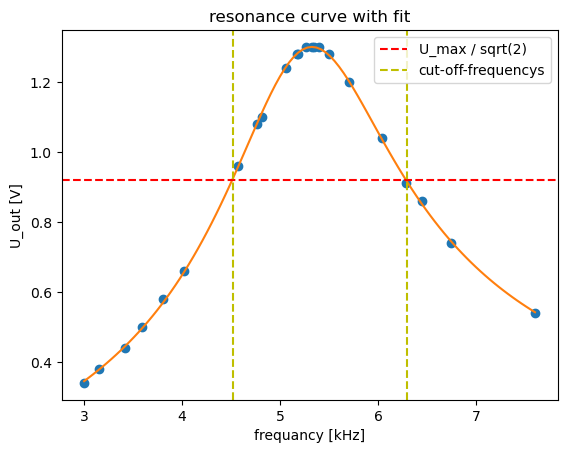

In [40]:
##### 3.2.3
# to do

L = 0.01
C = 100 * 10**(-9)
R = 1000
U_in = 1



# Q = omega_0 / d_omega
# d_omega = omega_o - omega_u
# are values where current / voltage has dropped by 1 / sqrt(2)



wdata = np.array([
    10000, 15000, 20000, 25000, 30000,
    31623, 35000, 40000, 45000, 50000,
    60000, 70000
])

Adata = np.array([
    0.110, 0.187, 0.316, 0.539, 0.948,
    1.000, 0.736, 0.496, 0.369, 0.287,
    0.205, 0.159
])

popt, pcov = curve_fit(fit, f, U_out, absolute_sigma=True)

a,b,c = popt 
print('theoretical Q =', R * np.sqrt(C / L))

print(a,b,c)

plt.plot(f, U_out, linestyle='', marker='o')
plt.plot(np.linspace(np.min(f), np.max(f), 100), fit(np.linspace(np.min(f), np.max(f), 100), a, b,c))
plt.axhline(1.3 / np.sqrt(2), linestyle = '--', color = 'r', label = 'U_max / sqrt(2)')
plt.axvline(4.52, linestyle = '--', color = 'y', label = 'cut-off-frequencys')
plt.axvline(6.29, linestyle = '--', color = 'y')
plt.title('resonance curve with fit')
plt.xlabel('frequancy [kHz]')
plt.ylabel('U_out [V]')
plt.legend()
print('from plot Q =', 5300 * 2 * np.pi / ((6290 - 4520) * 2 * np.pi))

In [70]:
U_max = fit(1 / np.sqrt(a * b), a, b ,c)
print(U_max)
aa = b
bb = (-1) * np.sqrt(2 / U_max**2 - c)
cc = (-1) / a
f_upper = np.abs(((-bb + np.sqrt(bb**2 - 4 * aa * cc)) / (2 * aa)))
f_lower = np.abs(((-bb - np.sqrt(bb**2 - 4 * aa * cc)) / (2 * aa)))
print(f_lower, f_upper)

print('fit Q =', 1 / np.sqrt(a * b) / ((f_upper - f_lower)))

1.3001037218171998
4.510002854681749 6.285240925150879
fit Q = 2.9991125925652837


[[  4.23         4.6          5.02         5.08         5.17
    5.27         5.4          5.58         5.84         6.14      ]
 [ 26.57787385  28.90265241  31.54159024  31.91858136  32.48406804
   33.11238657  33.92920066  35.06017401  36.69380219  38.57875779]
 [  3.01         3.79         4.76         4.85         4.97
    5.02         5.           4.84         4.43         3.82      ]
 [-85.         -74.         -50.         -43.         -34.
   -4.          48.          65.          75.          85.        ]]


Text(0.5, 0, 'frequency [kHz]')

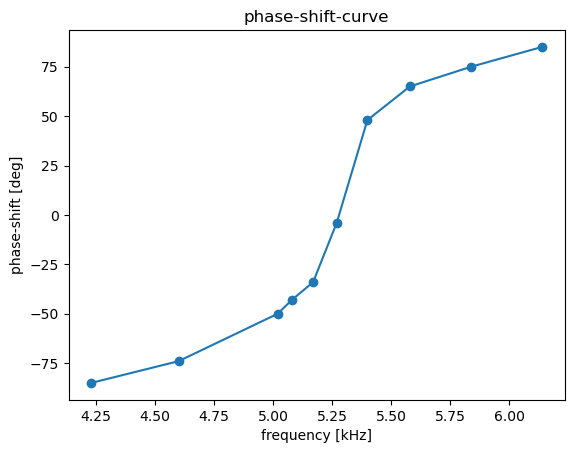

In [46]:
##### 3.2.4
f = np.array([4.23, 4.6, 5.02, 5.08, 5.17, 5.27, 5.4, 5.58, 5.84, 6.14])
I_L = np.array([1.86, 2.19, 2.52, 2.54, 2.56, 2.54, 2.46, 2.3, 2.01, 1.63])
I_C = np.array([1.15, 1.6, 2.24, 2.31, 2.41, 2.48, 2.54, 2.54, 2.42, 2.19])
phi = np.array([-85, -74, -50, -43, -34, -4, 48, 65, 75, 85])

print(np.array([f, f * 2 * np.pi, I_L + I_C, phi]))

plt.plot(f, phi, marker='o')
plt.title('phase-shift-curve')
plt.ylabel('phase-shift [deg]')
plt.xlabel('frequency [kHz]')

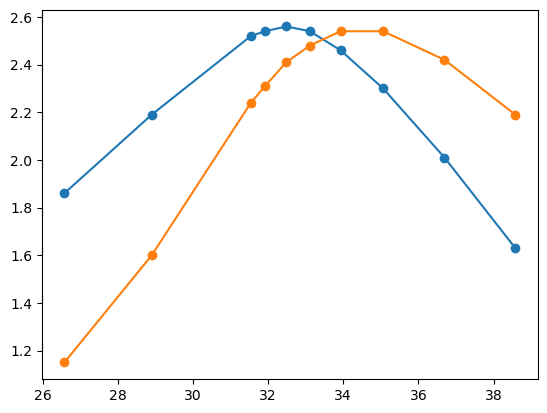

In [47]:
plt.plot(f * 2 * np.pi, I_L, marker='o')
plt.plot(f * 2 * np.pi, I_C, marker='o')

In [49]:
##### 3.2.5
C = np.array([10 * 10**(-9),
              100 * 10**(-9),
              1000 * 10**(-9)])
L = np.array([0.001,
              0.01])

print(1 / np.sqrt(L[0] * C) / 1000)
print(1 / np.sqrt(L[1] * C) / 1000)

#expected omega = 1 / sqrt(CL)

# L = 1 mH
f_0_1 = np.array([48.9, 15.7, 4.9])

# L = 10 mH
f_0_10 = np.array([16.4, 5.33 , 1.65]) #10, 100, 1000

print(f_0_1 * 2 * np.pi)
print(f_0_10 * 2 * np.pi)

[316.22776602 100.          31.6227766 ]
[100.         31.6227766  10.       ]
[307.24776152  98.64600932  30.78760801]
[103.04423904  33.48937769  10.36725576]


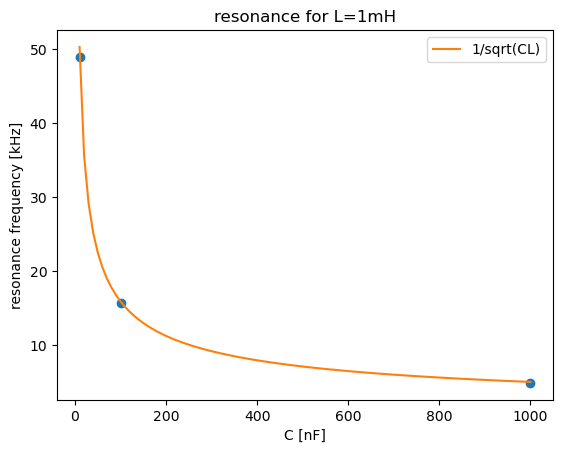

In [66]:
plt.plot(C * 10**9, f_0_1, marker='o', linestyle='')
plt.plot(np.linspace(np.min(C), np.max(C), 100) * 10**9, 1 / np.sqrt(L[0] * np.linspace(np.min(C), np.max(C), 100)) / (1000 * 2 * np.pi), label='1/sqrt(CL)')
plt.title('resonance for L=1mH')
plt.xlabel('C [nF]')
plt.ylabel('resonance frequency [kHz]')
plt.legend()

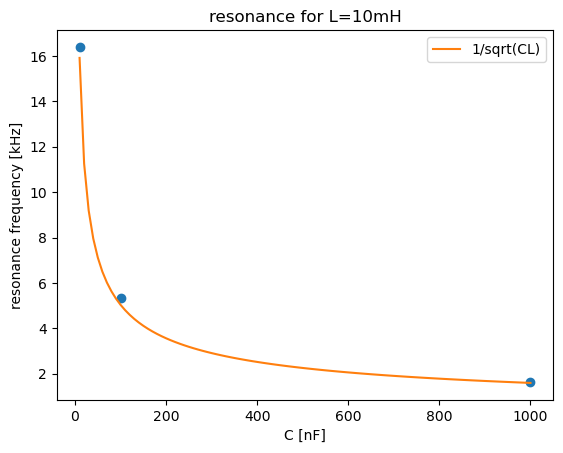

In [68]:
plt.plot(C * 10**9, f_0_10, marker='o', linestyle='')
plt.plot(np.linspace(np.min(C), np.max(C), 100) * 10**9, 1 / np.sqrt(L[1] * np.linspace(np.min(C), np.max(C), 100)) / (1000 * 2 * np.pi), label='1/sqrt(CL)')
plt.title('resonance for L=10mH')
plt.xlabel('C [nF]')
plt.ylabel('resonance frequency [kHz]')
plt.legend()

In [19]:
##### 3.2.6
# square signal